# Rede de Lieb 2D

In [1]:
from pythtb import *   # classe do modelo tight-binding
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Rectangle, FancyArrowPatch

# ── Estilo global ─────────────────────────────────────────────────────────────
rcParams['font.family']          = 'serif'
rcParams['font.serif']           = ['Times New Roman', 'DejaVu Serif']
rcParams['mathtext.fontset']     = 'stix'
rcParams['axes.linewidth']       = 0.8
rcParams['xtick.direction']      = 'in'
rcParams['ytick.direction']      = 'in'
rcParams['xtick.top']            = True
rcParams['ytick.right']          = True
rcParams['xtick.minor.visible']  = True
rcParams['ytick.minor.visible']  = True
rcParams['xtick.major.width']    = 0.8
rcParams['ytick.major.width']    = 0.8
rcParams['xtick.major.size']     = 4
rcParams['ytick.major.size']     = 4
rcParams['xtick.minor.size']     = 2.5
rcParams['ytick.minor.size']     = 2.5
rcParams['legend.frameon']       = True
rcParams['legend.framealpha']    = 0.9
rcParams['legend.edgecolor']     = '0.6'
rcParams['legend.fontsize']      = 15
rcParams['axes.labelsize']       = 17
rcParams['figure.titlesize']     = 20
rcParams['axes.titlesize']       = 18
rcParams['xtick.labelsize']      = 15
rcParams['ytick.labelsize']      = 15

ZERO = '#999999'

import os
def caminho_saida(nome):
    """Caminho Resultados/<nome>, criando a pasta se necessário."""
    pasta = os.path.join("Resultados")
    os.makedirs(pasta, exist_ok=True)
    return os.path.join(pasta, nome)


## Rede

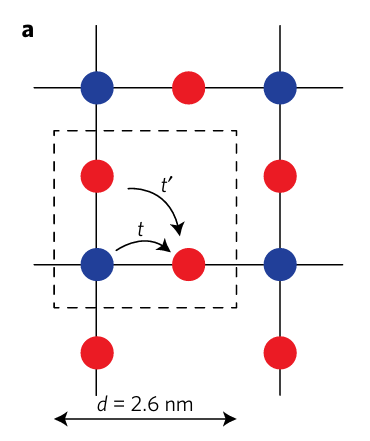

In [2]:
# Define vetores de rede
a = 2.6 # nm
rede = [
       [a, 0.0],         # a_1
       [0.0, a]          # a_2
       ]

# Define coordenadas dos orbitais (coordenadas de rede)
orbitais = [
           [0.0, 0.0],   # azul (no meio da rede -> \Gamma point)
           [1./2., 0.0], # vermelho (direita)
           [0.0, 1./2.]  # vermelho (cima)
           ]

## Hamiltoniano

In [3]:
t = -1.0   # hopping vizinho (unidade de energia)

# Hoppings entre primeiros vizinhos (azul-vermelho): (i, j, [vetor de rede da célula que contém j])
HOPS_NN = [
    (0, 1, [ 0,  0]),   # (0, 0)-(+1/2, 0)
    (0, 2, [ 0,  0]),   # (0, 0)-(0, +1/2)
    (0, 1, [-1,  0]),   # (0, 0)-(-1/2, 0)
    (0, 2, [ 0, -1]),   # (0, 0)-(0, -1/2)
]

# Hoppings entre próximos vizinhos (vermelho-vermelho)
HOPS_NNN = [
    (1, 2, [ 0,  0]),   # (+1/2, 0)-(0, +1/2)
    (1, 2, [ 1,  0]),   # (+1/2, 0)-(1, +1/2)
    (1, 2, [ 0, -1]),   # (+1/2, 0)-(0, -1/2)
    (1, 2, [ 1, -1]),   # (+1/2, 0)-(1, -1/2)
]


def constroi_modelo(delta, fator_tp):
    """Rede de Lieb com on-site eA=-delta, eB=+delta, hopping t e t' = fator_tp * t."""
    eA, eB = -delta/2, delta/2
    tp = fator_tp * t

    lat = Lattice(lat_vecs=rede, orb_vecs=orbitais, periodic_dirs=[0, 1])
    modelo = TBModel(lattice=lat, spinful=False)
    modelo.set_onsite([eA, eB, eB])

    for i, j, R in HOPS_NN:
        modelo.set_hop(t, i, j, R)
    if tp != 0.0:
        for i, j, R in HOPS_NNN:
            modelo.set_hop(tp, i, j, R)
    return modelo

## Funções de plot

In [4]:
def rotulo_caso_rede(fator_tp):
    """Rótulo (mathtext) e sufixo de arquivo de cada caso."""
    if fator_tp == 0:
        hop = r"$t^{\prime}=0$"
    elif np.isclose(fator_tp, np.sqrt(2)):
        hop = r"$t^{\prime}=\sqrt{2}\,t$"
    else:
        hop = rf"$t^{{\prime}}={fator_tp:g}\,t$"
    sufixo = ("_t_" if fator_tp != 0 else "")
    return f"{hop}", sufixo

def rotulo_caso_bandas(delta, fator_tp):
    """Rótulo (mathtext) e sufixo de arquivo de cada caso."""
    on  = r"$\epsilon_A = \epsilon_B$" if delta == 0 else r"$\epsilon_A \neq \epsilon_B$"
    if fator_tp == 0:
        hop = r"$t^{\prime}=0$"
    elif np.isclose(fator_tp, np.sqrt(2)):
        hop = r"$t^{\prime}=\sqrt{2}\,t$"
    else:
        hop = rf"$t^{{\prime}}={fator_tp:g}\,t$"
    sufixo = ("_eA_eB" if delta != 0 else "") + ("_t_" if fator_tp != 0 else "")
    return f"{on} e {hop}", sufixo

def rotulo_onsite(delta):
    """Rótulo (mathtext) da energia de sítio."""
    return r"$\epsilon_A = \epsilon_B$" if delta == 0 else r"$\epsilon_A \neq \epsilon_B$"


def desenha_rede(ax, fator_tp):
    """Desenha a rede de Lieb (sítios, hoppings, vetores de rede e célula unitária)."""
    M = np.array(rede)
    pos = lambda i, R=(0, 0): (np.array(orbitais[i]) + np.array(R)) @ M
    cor_sitio = {0: '#1f4e9c', 1: '#c0392b', 2: '#c0392b'}

    hops = [(i, j, R, 'nn') for i, j, R in HOPS_NN]
    if fator_tp != 0:
        hops += [(i, j, R, 'nnn') for i, j, R in HOPS_NNN]


    # célula unitária
    ax.add_patch(Rectangle((0, 0), a, a, fill=False, ls='--', lw=0.8, ec=ZERO, zorder=0))

    # ligações: uma seta curva (meia-seta aberta) por sentido, para que as duas
    # direções de cada hopping nunca se sobreponham e fiquem sempre visíveis
    extremos = []
    segmentos = {}
    for i, j, R, tipo in hops:
        R = np.array(R)
        for p, q in [(pos(i), pos(j, R)), (pos(j), pos(i, -R))]:
            chave = frozenset([tuple(np.round(p, 6)), tuple(np.round(q, 6))])
            segmentos.setdefault(chave, (p, q, tipo))
            extremos += [(p, None), (q, None)]

    for p, q, tipo in segmentos.values():
        if tipo == 'nn':
            estilo = dict(color='0.25', lw=1.3, mutation_scale=10, alpha=1.0)
        else:
            estilo = dict(color='#2a9d8f', lw=0.9, mutation_scale=8, alpha=0.8)
        for ini, fim in [(p, q), (q, p)]:          # mesmo rad -> curvaturas opostas
            ax.add_patch(FancyArrowPatch(ini, fim, arrowstyle='->', connectionstyle='arc3,rad=0.15',
                                         shrinkA=4, shrinkB=4, zorder=1, **estilo))

    # sítios: célula central cheios, imagens periódicas esmaesmaecidas
    centrais = {tuple(np.round(pos(i), 6)) for i in range(len(orbitais))}
    vistos = set()
    for p, _ in extremos:
        chave = tuple(np.round(p, 6))
        if chave in vistos:
            continue
        vistos.add(chave)
        # identifica a qual orbital pertence
        frac = np.round(np.linalg.solve(M.T, p) % 1.0, 6) % 1.0
        i = next(k for k, o in enumerate(orbitais) if np.allclose(frac, np.array(o) % 1.0))
        central = chave in centrais
        ax.scatter(*p, s=70 if central else 45, c=cor_sitio[i], alpha=1 if central else 0.35,
                   edgecolors='k' if central else 'none', linewidths=0.6, zorder=3)

    # vetores de rede
    for k, (v, lab) in enumerate(zip(M, [r"$\vec{a}_1$", r"$\vec{a}_2$"])):
        ax.annotate('', xy=v, xytext=(0, 0), zorder=2,
                    arrowprops=dict(arrowstyle='-|>', color='#1f4e9c', lw=1.4, shrinkA=0, shrinkB=0))
        dx, dy = (0.0, 0.08 * a) if k == 0 else (-0.10 * a, 0.0)
        ax.text(v[0] + dx + (0.04*a if k == 0 else 0), v[1] + dy, lab, color='#1f4e9c',
                ha='center', va='bottom' if k == 0 else 'center', fontsize=12)

    ax.set_aspect('equal')
    ax.set_xlim(-0.65*a, 1.2*a)
    ax.set_ylim(-0.65*a, 1.2*a)
    ax.set_xlabel(r"$x$ (nm)")
    ax.set_ylabel(r"$y$ (nm)")
    ax.set_title(rotulo_caso_rede(fator_tp)[0])


# ── Zona de Brillouin (apenas espaço recíproco) ───────────────────────────────
def desenha_zb(ax):
    """1ª zona de Brillouin da rede quadrada, em k (nm^-1): vetores recíprocos b_1 e b_2,
    pontos de alta simetria Γ, X, M e caminho Γ–X–M–Γ. Não há átomos: tudo está no espaço recíproco."""
    B = 2*np.pi*np.linalg.inv(np.array(rede)).T          # linhas = b_1, b_2 (a_i . b_j = 2π δ_ij)
    cart = lambda k_red: np.array(k_red) @ B             # coordenadas reduzidas -> k cartesiano
    L = np.pi / a                                        # meia largura da zona
    COR_K, COR_PT = '#e08a1e', '0.25'

    # zona de Brillouin
    ax.add_patch(Rectangle((-L, -L), 2*L, 2*L, fill=False, ls='--', lw=0.8, ec=ZERO, zorder=0))

    # vetores da rede recíproca
    for k, (v, lab) in enumerate(zip(B, [r"$\vec{b}_1$", r"$\vec{b}_2$"])):
        ax.annotate('', xy=v, xytext=(0, 0), zorder=1,
                    arrowprops=dict(arrowstyle='-|>', color='#1f4e9c', lw=1.4, shrinkA=0, shrinkB=0))
        dx, dy = (0.0, 0.16*L) if k == 0 else (-0.20*L, 0.0)
        ax.text(v[0] + dx + (0.08*L if k == 0 else 0), v[1] + dy, lab, color='#1f4e9c',
                ha='center', va='bottom' if k == 0 else 'center', fontsize=12)

    # caminho Γ–X–M–Γ
    caminho = [[0., 0.], [0., 1./2.], [1./2., 1./2.], [0., 0.]]
    pts = [cart(k) for k in caminho]
    for p, q in zip(pts[:-1], pts[1:]):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=14, color=COR_K,
                                     lw=2.0, shrinkA=7, shrinkB=7, zorder=2))

    # pontos de alta simetria: os do caminho cheios; os equivalentes por simetria, esmaecidos
    for k in [(0, -.5), (.5, 0), (-.5, 0), (-.5, .5), (.5, -.5), (-.5, -.5)]:
        ax.scatter(*cart(k), s=45, c=COR_PT, alpha=0.3, edgecolors='none', zorder=3)
    rotulos = [r'$\Gamma$', r'$X$', r'$M$']
    desloc  = [(-0.17*L, -0.20*L), (-0.17*L, 0.0), (0.12*L, 0.12*L)]
    for p, rot, (dx, dy) in zip(pts[:3], rotulos, desloc):
        ax.scatter(*p, s=70, c=COR_PT, edgecolors='k', linewidths=0.6, zorder=4)
        ax.text(p[0] + dx, p[1] + dy, rot, fontsize=16, ha='center', va='center', zorder=5)

    ax.set_aspect('equal')
    ax.set_xlim(-1.3*L, 2.4*L)
    ax.set_ylim(-1.3*L, 2.4*L)
    ax.set_xlabel(r"$k_x$ (nm$^{-1}$)")
    ax.set_ylabel(r"$k_y$ (nm$^{-1}$)")
    ax.set_title("Zona de Brillouin")


def desenha_bandas(ax, modelo):
    """Estrutura de bandas ao longo de Γ–X–M–Γ, desenhada em `ax` (sem rótulos de eixo)."""
    caminho = [[0., 0.], [0., 1./2.], [1./2., 1./2.], [0., 0.]]
    rotulos = (r'$\Gamma$', r'$X$', r'$M$', r'$\Gamma$')

    k_vec, k_dist, k_node = modelo.k_path(caminho, 129, report=False)
    evals = np.asarray(modelo.solve_ham(k_vec))
    if evals.shape[0] == len(k_dist):     # garante formato (n_bandas, n_k) em qualquer versão do pythtb
        evals = evals.T

    cores = ['#1f4e9c', '#e08a1e', '#c0392b']
    ax.axhline(0, color=ZERO, lw=0.8, ls='--', zorder=0)
    for x in k_node:
        ax.axvline(x, color='0.3', lw=0.5, zorder=0)
    for n, banda in enumerate(evals):
        ax.plot(k_dist, banda, color=cores[n % len(cores)], lw=1.8)
    ax.set_xlim(k_node[0], k_node[-1])
    ax.set_xticks(k_node)
    ax.set_xticklabels(rotulos)
    ax.xaxis.set_minor_locator(plt.NullLocator())   # só os pontos de alta simetria


# ── Montagem de painéis ───────────────────────────────────────────────────────
LETRAS = "abcdefghijkl"

def cria_painel(linhas, colunas, figsize, **kw):
    """Figura em grade (constrained layout); eixos compartilhados, (a), (b)... no canto de cada painel."""
    fig, axs = plt.subplots(linhas, colunas, figsize=figsize, layout='constrained', squeeze=False, **kw)
    for k, ax in enumerate(axs.ravel()):
        ax.set_title(f"({LETRAS[k]})", loc='left', fontsize=rcParams['axes.titlesize'])
    return fig, axs


def rotulo_linha(ax, texto):
    """Rótulo da linha, à direita do último painel dela."""
    ax.yaxis.set_label_position('right')
    ax.set_ylabel(texto, rotation=270, va='bottom', labelpad=6)


def cria_painel_casos(figsize, sharey=True):
    """Grade dos 4 casos: colunas = eA = eB / eA != eB (DELTAS); linhas = t' (FATORES_TP)."""
    fig, axs = cria_painel(len(FATORES_TP), len(DELTAS), figsize, sharex=True, sharey=sharey)
    for j, delta in enumerate(DELTAS):
        axs[0, j].set_title(rotulo_onsite(delta), loc='center')
    for i, fator_tp in enumerate(FATORES_TP):
        rotulo_linha(axs[i, -1], rotulo_caso_rede(fator_tp)[0])
    return fig, axs


## Loop sobre todas as versões
Cada combinação de `delta` (eA = eB ou eA ≠ eB) e `fator_tp` (t' = 0 ou t' = t / √2) gera a figura da rede e a das bandas, com os mesmos nomes de arquivo usados antes.

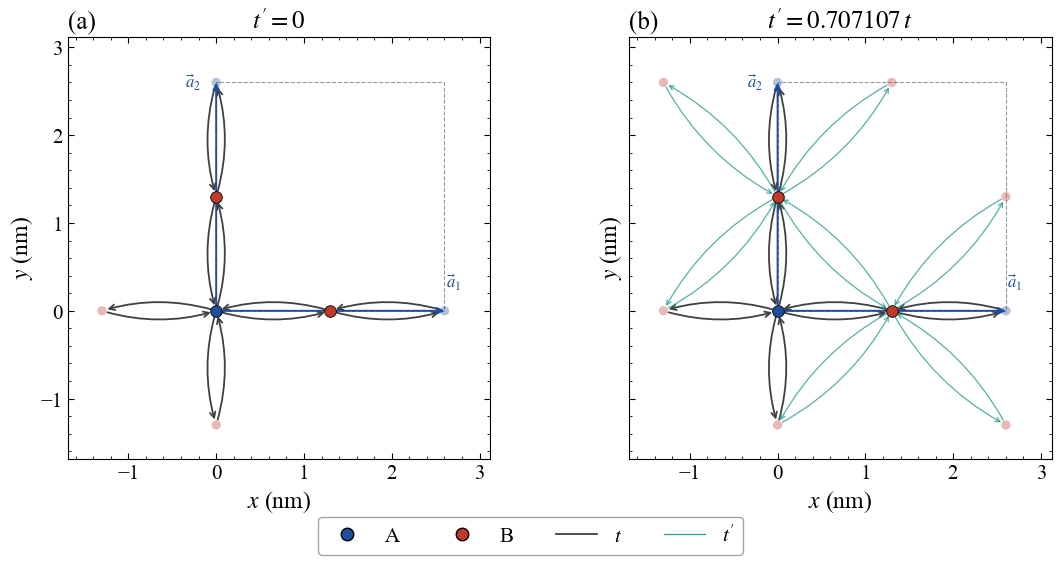

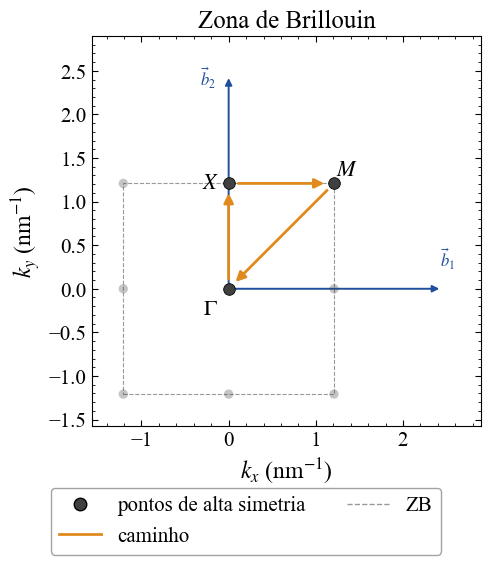

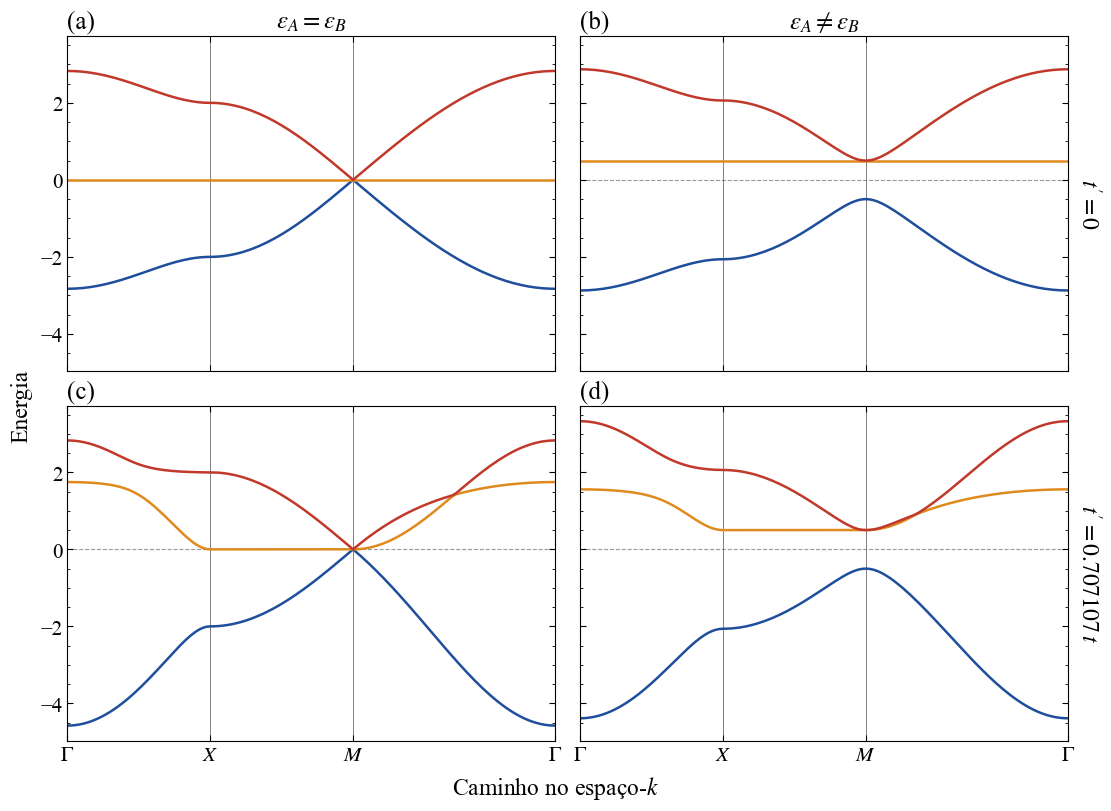

In [5]:
DELTAS     = [0.0, 1.0]   # 0 -> eA = eB ; 1 -> eA = -1, eB = +1
FATORES_TP = [0.0, 1/np.sqrt(2)]   # t' = fator * t

# ── Painel da rede: uma coluna por t' (a rede não depende de eA, eB) ──────────
from matplotlib.lines import Line2D

fig, axs = cria_painel(1, len(FATORES_TP), (5.6*len(FATORES_TP), 5.6), sharey=True)
for ax, fator_tp in zip(axs[0], FATORES_TP):
    desenha_rede(ax, fator_tp)
    ax.set_xlabel(r"$x$ (nm)")
axs[0, 0].set_ylabel(r"$y$ (nm)")
axs[0, 1].tick_params(labelleft=False)
leg = [Line2D([], [], marker='o', ls='', mfc='#1f4e9c', mec='k', ms=9, label="A"),
       Line2D([], [], marker='o', ls='', mfc='#c0392b', mec='k', ms=9, label="B"),
       Line2D([], [], color='0.25', lw=1.3, label=r"$t$")]
if any(f != 0 for f in FATORES_TP):
    leg.append(Line2D([], [], color='#2a9d8f', lw=0.9, label=r"$t^{\prime}$"))
fig.legend(handles=leg, loc='outside lower center', ncol=len(leg))
fig.savefig(caminho_saida("estrutura.pdf"), bbox_inches='tight')
plt.show()

# ── Zona de Brillouin com o caminho Γ–X–M–Γ ───────────────────────────────────
fig, ax = plt.subplots(figsize=(5.6, 5.6), layout='constrained')
desenha_zb(ax)
leg = [Line2D([], [], marker='o', ls='', mfc='0.25', mec='k', ms=9, label="pontos de alta simetria"),
       Line2D([], [], color='#e08a1e', lw=2.0, label="caminho"),
       Line2D([], [], color=ZERO, lw=1.0, ls='--', label="ZB")]
fig.legend(handles=leg, loc='outside lower center', ncol=2)
fig.savefig(caminho_saida("caminho_zb.pdf"), bbox_inches='tight')
plt.show()

# ── Painel das bandas: 2 x 2 (colunas = eA, eB; linhas = t') ──────────────────
fig, axs = cria_painel_casos((11, 8))
for i, fator_tp in enumerate(FATORES_TP):
    for j, delta in enumerate(DELTAS):
        desenha_bandas(axs[i, j], constroi_modelo(delta, fator_tp))
fig.supxlabel("Caminho no espaço-$k$", fontsize=rcParams['axes.labelsize'])
fig.supylabel("Energia", fontsize=rcParams['axes.labelsize'])
fig.savefig(caminho_saida("bandas.pdf"), bbox_inches='tight')
plt.show()


## Autovalores e autovetores (fat bands)

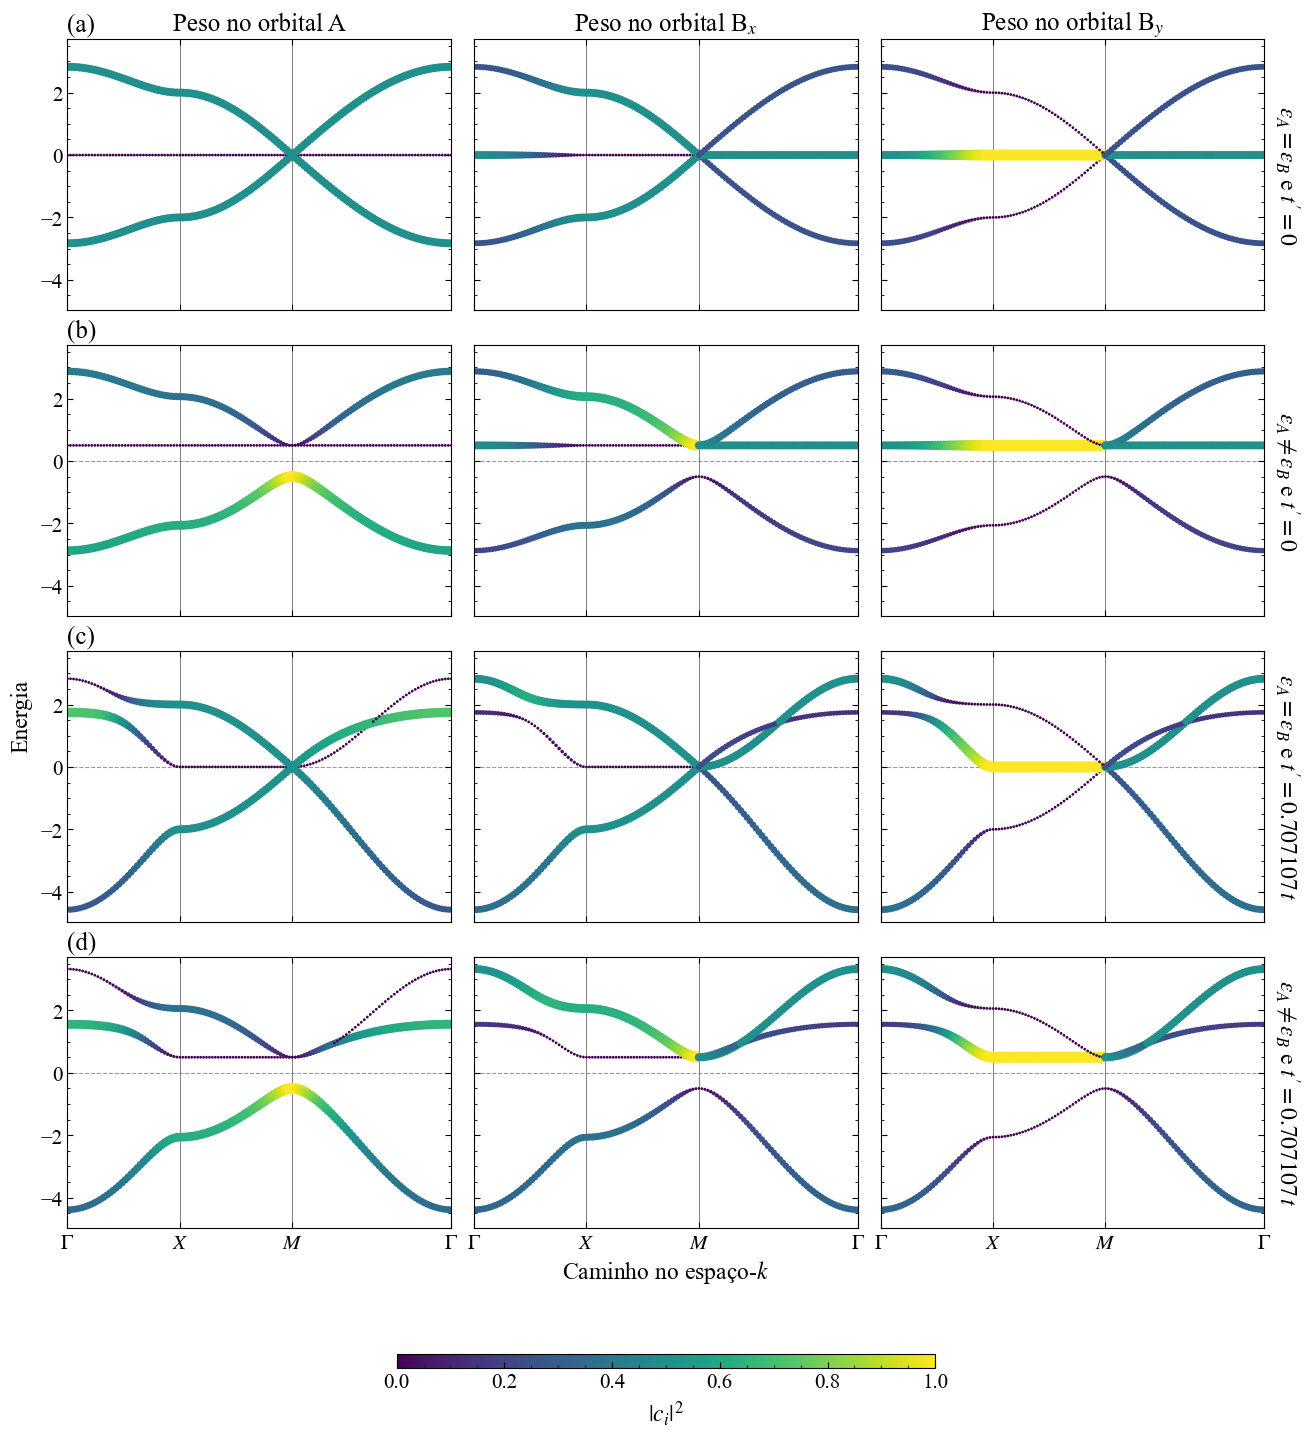

In [6]:
NOMES_ORB = ["A", "B$_x$", "B$_y$"]

def calcula_bandas_pesos(modelo, nk=129):
    """Autovalores e pesos orbitais |c_i|^2 ao longo de Γ–X–M–Γ."""
    caminho = [[0., 0.], [0., 1./2.], [1./2., 1./2.], [0., 0.]]
    k_vec, k_dist, k_node = modelo.k_path(caminho, nk, report=False)
    evals, evecs = modelo.solve_ham(k_vec, return_eigvecs=True)   # (nk, nb), (nk, nb, norb)
    pesos = np.abs(evecs)**2
    return k_dist, k_node, np.asarray(evals), pesos


def desenha_fatbands(axs_linha, modelo):
    """Fat bands de um caso: um gráfico por orbital; cor e tamanho de cada ponto ∝ |c_i|^2."""
    rotulos = (r'$\Gamma$', r'$X$', r'$M$', r'$\Gamma$')
    k_dist, k_node, evals, pesos = calcula_bandas_pesos(modelo)
    for i, ax in enumerate(axs_linha):
        ax.axhline(0, color=ZERO, lw=0.8, ls='--', zorder=0)
        for x in k_node:
            ax.axvline(x, color='0.3', lw=0.5, zorder=0)
        for n in range(evals.shape[1]):
            w = pesos[:, n, i]
            sc = ax.scatter(k_dist, evals[:, n], c=w, s=4 + 60*w, cmap='viridis',
                            vmin=0, vmax=1, edgecolors='none', zorder=2)
        ax.set_xlim(k_node[0], k_node[-1])
        ax.set_xticks(k_node)
        ax.set_xticklabels(rotulos)
        ax.xaxis.set_minor_locator(plt.NullLocator())
    return sc


# Painel: linhas = casos (a)–(d); colunas = orbitais. Uma única barra de cores.
casos = [(d, f) for f in FATORES_TP for d in DELTAS]
fig, axs = plt.subplots(len(casos), 3, figsize=(13, 3.3*len(casos) + 1), sharex=True, sharey=True,
                        layout='constrained', squeeze=False)
for r, (delta, fator_tp) in enumerate(casos):
    sc = desenha_fatbands(axs[r], constroi_modelo(delta, fator_tp))
    axs[r, 0].set_title(f"({LETRAS[r]})", loc='left', fontsize=rcParams['axes.titlesize'])
    rotulo_linha(axs[r, -1], rotulo_caso_bandas(delta, fator_tp)[0])
for ax, nome in zip(axs[0], NOMES_ORB):
    ax.set_title(f"Peso no orbital {nome}", loc='center')
axs[-1, 1].set_xlabel("Caminho no espaço-$k$")
fig.supylabel("Energia", fontsize=rcParams['axes.labelsize'])
fig.colorbar(sc, ax=axs, location='bottom', shrink=0.45, aspect=40, label=r"$|c_i|^2$")
fig.savefig(caminho_saida("fatbands.pdf"), bbox_inches='tight')
plt.show()


## DOS global de uma célula unitária (*Density of States*)

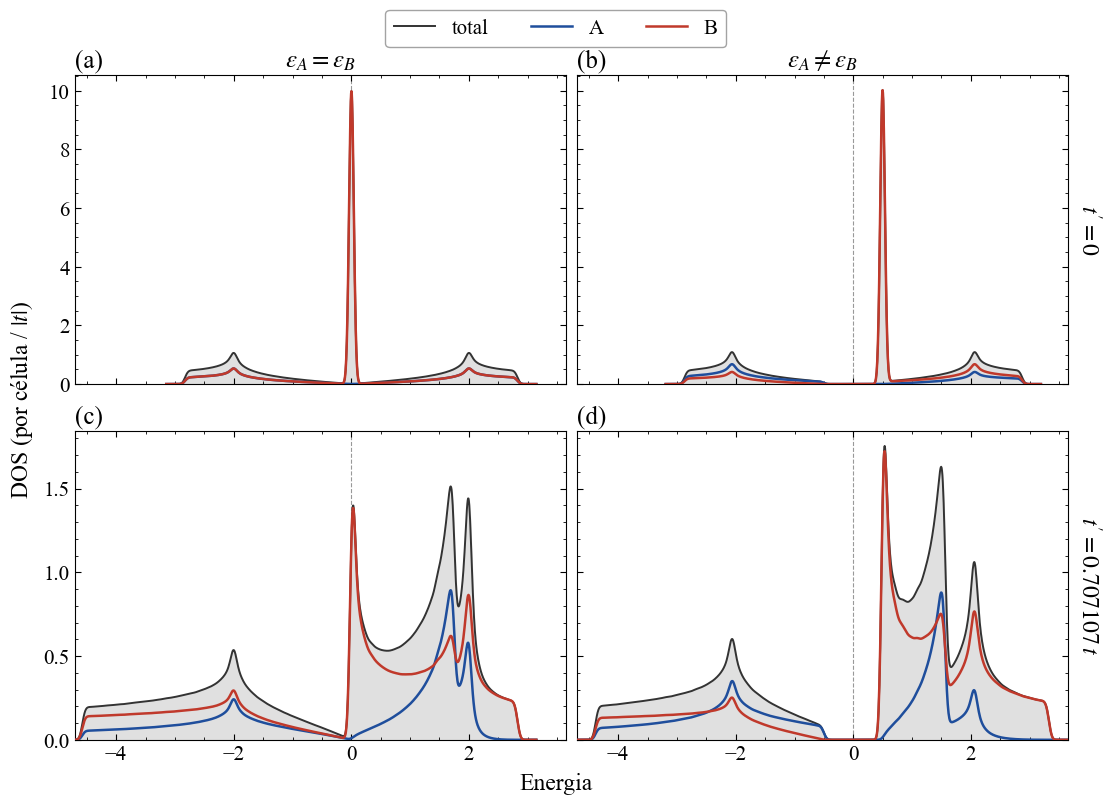

In [7]:
def calcula_dos(modelo, nmesh=300, eta=0.04, npts=1200):
    """DOS total e projetada por orbital (por célula unitária), alargamento gaussiano de largura eta."""
    k_mesh = modelo.k_uniform_mesh([nmesh, nmesh], include_endpoints=False)
    evals, evecs = modelo.solve_ham(k_mesh, return_eigvecs=True)
    pesos = np.abs(evecs)**2                                    # (nk, nb, norb)
    nk = evals.shape[0]

    E = np.linspace(evals.min() - 8*eta, evals.max() + 8*eta, npts)
    dE = E[1] - E[0]
    edges = np.append(E - dE/2, E[-1] + dE/2)
    x = np.arange(-int(6*eta/dE), int(6*eta/dE) + 1) * dE
    kernel = np.exp(-x**2/(2*eta**2)); kernel /= kernel.sum()

    def alarga(h):
        return np.convolve(h, kernel, mode='same') / (nk * dE)

    dos_total = alarga(np.histogram(evals.ravel(), bins=edges)[0].astype(float))
    dos_orb = np.array([alarga(np.histogram(evals.ravel(), bins=edges,
                                            weights=pesos[:, :, i].ravel())[0])
                        for i in range(pesos.shape[2])])
    return E, dos_total, dos_orb


def desenha_dos(ax, modelo):
    """DOS total e projeções em A e em B (B = B_x + B_y, equivalentes por simetria)."""
    E, dos, dos_orb = calcula_dos(modelo)
    dos_A, dos_B = dos_orb[0], dos_orb[1] + dos_orb[2]
    ax.axvline(0, color=ZERO, lw=0.8, ls='--', zorder=0)
    ax.fill_between(E, dos, color='0.88', zorder=1)
    ax.plot(E, dos,   color='0.2',     lw=1.4, zorder=2, label="total")
    ax.plot(E, dos_A, color='#1f4e9c', lw=1.8, zorder=3, label="A")
    ax.plot(E, dos_B, color='#c0392b', lw=1.8, zorder=3, label="B")
    ax.set_xlim(E[0], E[-1])
    return dos.max()


# Painel 2 x 2; eixo y compartilhado por linha (a escala depende de t'); legenda única
fig, axs = cria_painel_casos((11, 8), sharey='row')
for i, fator_tp in enumerate(FATORES_TP):
    topo = max(desenha_dos(axs[i, j], constroi_modelo(delta, fator_tp)) for j, delta in enumerate(DELTAS))
    axs[i, 0].set_ylim(0, 1.05*topo)
fig.supxlabel("Energia", fontsize=rcParams['axes.labelsize'])
fig.supylabel(r"DOS (por célula / $|t|$)", fontsize=rcParams['axes.labelsize'])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside upper center', ncol=3)
fig.savefig(caminho_saida("dos.pdf"), bbox_inches='tight')
plt.show()


## LDOS (DOS local por sítio)

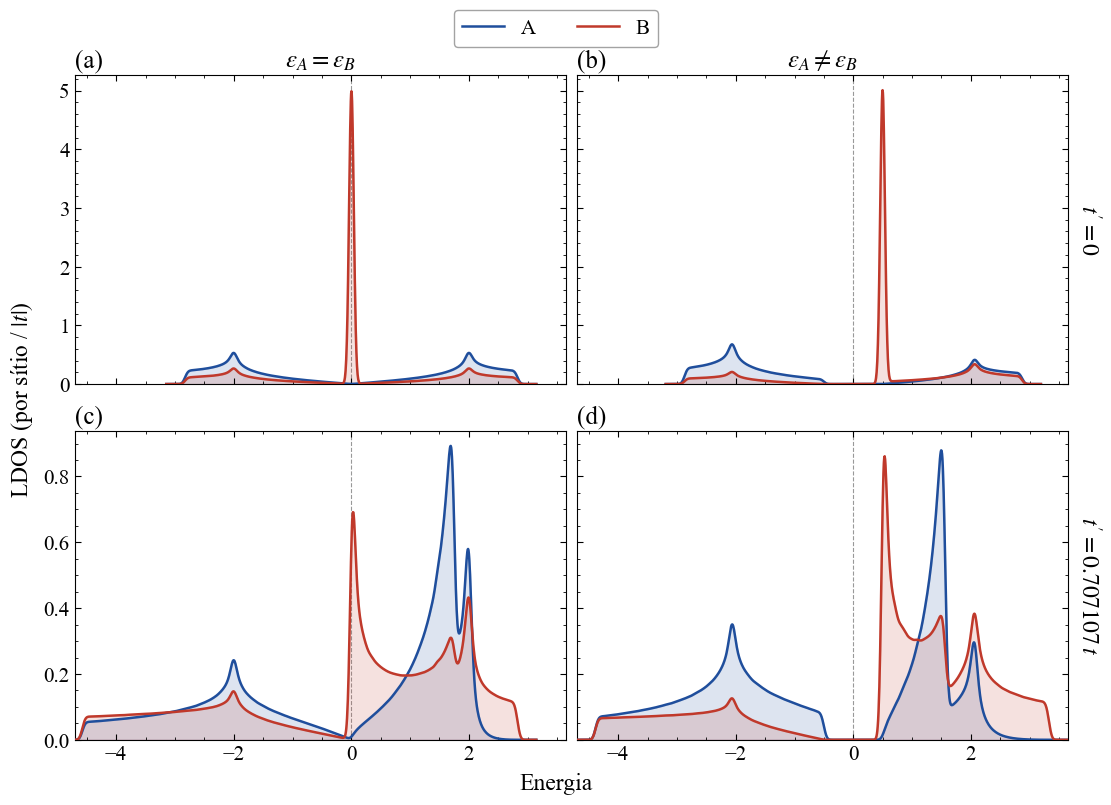

In [8]:
def desenha_ldos(ax, modelo):
    """LDOS por sítio (cristal infinito): peso |c_i|^2 do orbital i em cada estado, em vez do peso total.
    Cada curva integra a 1 estado por sítio. B_x e B_y são equivalentes por simetria; se não forem, B_y é mostrado à parte."""
    E, dos, dos_orb = calcula_dos(modelo)
    ldos_A, ldos_Bx, ldos_By = dos_orb
    ax.axvline(0, color=ZERO, lw=0.8, ls='--', zorder=0)
    ax.fill_between(E, ldos_A,  color='#1f4e9c', alpha=0.15, zorder=1)
    ax.fill_between(E, ldos_Bx, color='#c0392b', alpha=0.15, zorder=1)
    ax.plot(E, ldos_A,  color='#1f4e9c', lw=1.8, zorder=3, label="A")
    ax.plot(E, ldos_Bx, color='#c0392b', lw=1.8, zorder=3, label="B")
    if not np.allclose(ldos_Bx, ldos_By, atol=1e-6):
        ax.plot(E, ldos_By, color='#2a9d8f', lw=1.5, ls='--', zorder=3, label=r"B$_y$")
    ax.set_xlim(E[0], E[-1])
    return max(ldos_A.max(), ldos_Bx.max(), ldos_By.max())


fig, axs = cria_painel_casos((11, 8), sharey='row')
for i, fator_tp in enumerate(FATORES_TP):
    topo = max(desenha_ldos(axs[i, j], constroi_modelo(delta, fator_tp)) for j, delta in enumerate(DELTAS))
    axs[i, 0].set_ylim(0, 1.05*topo)
fig.supxlabel("Energia", fontsize=rcParams['axes.labelsize'])
fig.supylabel(r"LDOS (por sítio / $|t|$)", fontsize=rcParams['axes.labelsize'])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside upper center', ncol=2)
fig.savefig(caminho_saida("ldos.pdf"), bbox_inches='tight')
plt.show()


## Ocupação dos níveis: $D(E)\,f(E)$

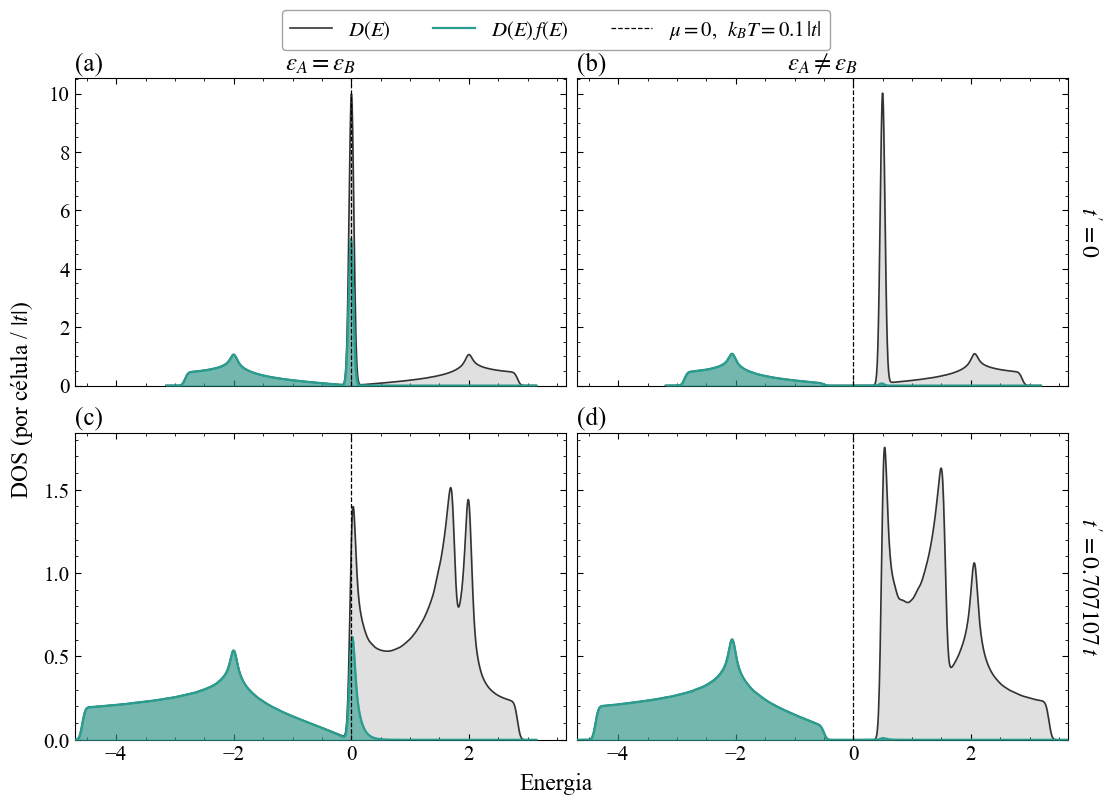

In [9]:
from scipy.special import expit

MU = 0.0     # potencial químico (unidades de |t|)
KT = 0.1     # k_B T (unidades de |t|)

def fermi(E, mu=MU, kT=KT):
    """Fermi–Dirac f(E) = 1 / (exp((E - mu)/kT) + 1)."""
    return expit(-(E - mu) / kT)


def desenha_ocupacao(ax, modelo, mu=MU, kT=KT):
    """DOS total D(E) e D(E) f(E): a parte preenchida é a ocupada. Retorna o máximo de D."""
    E, dos, _ = calcula_dos(modelo)
    ocupados = dos * fermi(E, mu, kT)
    ax.fill_between(E, dos, color='0.88', zorder=1)
    ax.plot(E, dos, color='0.2', lw=1.2, zorder=2, label=r"$D(E)$")
    ax.fill_between(E, ocupados, color='#2a9d8f', alpha=0.6, zorder=3)
    ax.plot(E, ocupados, color='#2a9d8f', lw=1.6, zorder=4, label=r"$D(E)\,f(E)$")
    ax.axvline(mu, color='k', lw=0.9, ls='--', zorder=5, label=rf"$\mu={mu:g}$,  $k_BT={kT:g}\,|t|$")
    ax.set_xlim(E[0], E[-1])
    return dos.max()


fig, axs = cria_painel_casos((11, 8), sharey='row')
for i, fator_tp in enumerate(FATORES_TP):
    topo = max(desenha_ocupacao(axs[i, j], constroi_modelo(delta, fator_tp)) for j, delta in enumerate(DELTAS))
    axs[i, 0].set_ylim(0, 1.05*topo)
fig.supxlabel("Energia", fontsize=rcParams['axes.labelsize'])
fig.supylabel(r"DOS (por célula / $|t|$)", fontsize=rcParams['axes.labelsize'])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside upper center', ncol=3)
fig.savefig(caminho_saida("dos_ocupacao.pdf"), bbox_inches='tight')
plt.show()


## Sobre o uso de IA generativa

Foi usada apenas para auxílio nos códigos de plotagem de gráficos e montagem de painéis. O código de modelagem *tight-binding* via PythTB não foi feito por IA, nem as disc 